# 1. MONTH-END FIX - HYPOTHESIS DEFINITION & BASELINE BACKTEST

This notebook formulates the quantitative hypothesis and establishes the baseline backtest for the **Month-End Fix (v1)** strategy on **hourly Axi EURGBP CFD bars (UTC, converted from the broker's server time; the rules are expressed in London local time)**.

### 1.1 CORE QUANTITATIVE HYPOTHESIS
- **Month-end fix flow**: on the last business day of the month, global portfolios rebalance their currency hedges and benchmark-linked flows are executed against the **4 pm London WM/Reuters fix**. The order flow builds up in the hours before the fix, so EURGBP drifts in the direction of that flow. Declared **before seeing data**: **short EURGBP** (sell EUR / buy GBP). The opposite direction is not tested.
- **Only that day**: the same 12:00 -> 16:00 window on any other business day carries no such flow. Tested in section 4.1.
- **A specific window, not a drift**: the mean gross return of the rule must beat random windows of the same length on non-target days (5,000-draw permutation). Tested in section 4.2.
- **Consistent, not carried by a few trades**: positive in most calendar years and still positive without the best 10% of trades. Tested in sections 4.3-4.4.
- **Costs are small, so the edge must be real**: with a ~1 bp spread the gross edge must be at least 3x the spread (section 8).

### 1.2 FROZEN STRATEGY RULES
| Rule Component | Specification |
| :--- | :--- |
| **Instrument** | EURGBP CFD (Axi), 1-hour bars (UTC), Axi MT5 history |
| **Calendar Filter** | Last business day (Monday to Friday) of each month, London local date. A calendar rule: no price signal, no lookahead |
| **Entry** | **Sell** at the **OPEN** of the 12:00 London bar: `Entry = Open * (1 - cost)` |
| **Exit** | **Buy back** at the **OPEN** of the 16:00 London bar (4 bars later, the fix hour): `Exit = Open * (1 + cost)` |
| **Direction** | **Short only**, no stop, no take profit (position size is the risk management) |
| **Trading Costs** | `cost_bps_per_side` per side (BID prices: one spread round trip in total) + **0 nights** of swap (intraday, never crosses the rollover) |
| **Position Sizing** | (a) **100 % of capital** (per-trade reference) · (b) **`size_fraction`** of capital (1x ideal) · (c) **minimum lot** (0.01) on 1,000 and 2,000 (what the robot can really trade) |
| **Parameters** | **None to optimise.** No grid, no sweep of windows, days or parameters |

### 1.3 PROVENANCE & VERDICT RULES
- **Naked window**: the same 12:00 -> 16:00 short on every business day. The control group for everything below.
- **Screening (done before this notebook)**: n 118, net +5.0 bps, t 2.07, permutation p 0.00, edge 5.8x the spread. Fails t OOS (0.45), years positive (70%), the multiple-testing corrected t, and the mean without the best 10% (+0.2 bps). **CASI-PASA, not a strict CASI.** The same pipeline gave STOP for EURUSD, GBPUSD and USDCHF, so the GBP leg is shared with the other near-misses.
- **What this notebook does**: it re-runs the **frozen** rule through the full pipeline and applies the screen (PASA / CASI / STOP). It changes nothing. A CASI is only reviewed once, without changing rules, on **fresh data** (candles after `split.fresh_start`).
- **Screen thresholds**: base = Monday Effect (t >= 2.0, PF >= 1.3, n OOS >= 30, t OOS >= 1.645, 75% positive years, permutation p < 0.05, positive mean without the best 10%, edge >= 3x spread, intrabar DD inside -9% with the minimum lot, correlation < 0.3). The t is also corrected for the number of tests run so far (`K_TESTS`).

> **AXI VARIANT NOTE**: the screening ran on the same broker candles. This notebook confirms the vehicle and the pipeline; it does not give independent evidence. Independent evidence can only come from the fresh data. With ~12 trades a year, expect ~3 years of fresh candles before n OOS >= 36.

### 1.4 STRATEGY PARAMETERS

In [35]:
VARIANT = "v1_eurgbp"
HARD_LIMIT = 0.09
CAPITALS = (1_000.0, 2_000.0)      # target capital range of the portfolio

## 2. IMPORTS AND CONFIG

In [36]:
import os
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    # Walk up from start (cwd by default) and return the first folder that contains `name`.
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR   = find_upwards('variants')                  # edge folder (notebooks, engine and variants/ live together)
utils_path = str(find_upwards('utils') / 'utils')      # research_development/utils
for p in (utils_path, str(EDGE_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics
from metrics import sharpe_ratio, max_drawdown
import month_end_fix_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # resets ENGINE_DEFAULTS: nothing leaks between variants

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg         = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR     = cfg["run_dir"]
TICKER      = cfg["instrument"]["ticker"]
DATA_START  = cfg["instrument"]["start"]
OOS_START   = cfg["oos_start_ts"]
FRESH_START = cfg["fresh_start_ts"]
P           = cfg["params"]
SIDE, ENTRY_H, EXIT_H, COST_BPS = P["side"], P["entry_hour"], P["exit_hour"], P["cost_bps_per_side"]
HOLD        = EXIT_H - ENTRY_H
SPREAD_BPS  = 2 * COST_BPS                  # BID prices: one spread round trip = 2 half-spreads
SIZE_FRAC   = eng.ENGINE_DEFAULTS["size_fraction"]
CONTRACT_SIZE, MIN_LOT, LOT_STEP = (eng.ENGINE_DEFAULTS[k] for k in ("contract_size", "min_lot", "lot_step"))
SIGN        = eng._sign(SIDE)
PPY         = 252   # FX trades on business days: annualisation for Sharpe
CAP_MAIN    = max(CAPITALS)

# Frozen rules, passed as-is to every backtest call in this notebook
RULES = dict(side=SIDE, entry_hour=ENTRY_H, exit_hour=EXIT_H, cost_bps_per_side=COST_BPS)

# ---- Screen thresholds: every PASS / FAIL in this notebook is judged against these ----
T_MIN, T_OOS_MIN, PF_MIN = 2.0, 1.645, 1.3   # t-stat of the mean net trade (full period / OOS), Profit Factor
N_OOS_MIN            = 30                     # minimum OOS trades to say anything
K_TESTS              = 17                     # tests run so far (keep in sync with the research log); t is corrected with it
ALPHA                = 0.05                   # significance level of the statistical tests
T_CORR               = float(stats.norm.ppf(1 - ALPHA / K_TESTS))   # Bonferroni-style corrected threshold
YEARS_POS_MIN        = 0.75                   # share of calendar years (with trades) that must be profitable
TRIM_SHARE           = 0.10                   # drop the best 10 % of trades: the mean must stay > 0
EDGE_SPREAD_MIN      = 3.0                    # gross edge / round-trip spread
DECAY_MAX            = 0.50                   # IS -> OOS decay >= 50 % = immediate discard
CORR_MAX             = 0.30                   # |correlation| of daily returns with the other edges
CASI_TOL             = 0.10                   # CASI = one gate failing by < 10 % of its threshold
PERM_DRAWS, PERM_SEED = 5_000, 7              # permutation test
MAX_SIGNAL_LOSS      = 0.05                   # max share of month-ends without a valid window (gaps)
MIN_TRADES_PER_YEAR  = 10                     # a full calendar year has 12 month-ends

# ---- PASS / FAIL registry: each section registers its checks here, section 8 groups them ----
CHECKS = []

def check(section, name, passed, detail="", quiet=False):
    # Register one check. passed: True -> PASS, False -> FAIL, None -> SKIP (not applicable).
    # Re-running a cell overwrites its previous entries instead of duplicating them.
    status = "SKIP" if passed is None else ("PASS" if bool(passed) else "FAIL")
    entry = {"section": section, "name": name, "status": status, "detail": detail}
    for i, c in enumerate(CHECKS):
        if c["section"] == section and c["name"] == name:
            CHECKS[i] = entry
            break
    else:
        CHECKS.append(entry)
    if not quiet:
        print(f"   [{status}] {name}" + (f"  ->  {detail}" if detail else ""))
    return status

print("Imports complete.")
print(f"Loaded month_end_fix_engine from: {eng.__file__}")
print(f"Edge dir: {EDGE_DIR}")
print(f"Variant: {cfg['id']} | {TICKER} | {SIDE} {ENTRY_H:02d}:00 -> {EXIT_H:02d}:00 London on the last business day | "
      f"{COST_BPS:g} bps/side ({SPREAD_BPS:g} bp round trip)")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap: {eng.ENGINE_DEFAULTS['financing_bps_per_night']:g} bps/night (intraday)")
print(f"CFD: contract {CONTRACT_SIZE:,.0f} | min lot {MIN_LOT:g} | step {LOT_STEP:g} | capitals {', '.join(f'{c:,.0f}' for c in CAPITALS)} | hard limit -{HARD_LIMIT:.0%}")
print(f"Screen: t >= {T_MIN:g} (corrected {T_CORR:.2f} with k={K_TESTS}) | t OOS >= {T_OOS_MIN:g} | PF >= {PF_MIN:g} | n OOS >= {N_OOS_MIN} | perm p < {ALPHA:g}")
print(f"OOS from {OOS_START:%Y-%m-%d} | fresh data from {FRESH_START:%Y-%m-%d}" if FRESH_START is not None else f"OOS from {OOS_START:%Y-%m-%d}")
print(f"Run folder: {RUN_DIR}")

Imports complete.
Loaded month_end_fix_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/EURGBP_Month_End_Fix/month_end_fix_engine.py
Edge dir: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/EURGBP_Month_End_Fix
Variant: MONTHEND_FIX.eurgbp.cfd.v1 | eurgbp | short 12:00 -> 16:00 London on the last business day | 0.5 bps/side (1 bp round trip)
Data source: csv_hourly | swap: 0 bps/night (intraday)
CFD: contract 100,000 | min lot 0.01 | step 0.01 | capitals 1,000, 2,000 | hard limit -9%
Screen: t >= 2 (corrected 2.75 with k=17) | t OOS >= 1.645 | PF >= 1.3 | n OOS >= 30 | perm p < 0.05
OOS from 2024-01-01 | fresh data from 2026-11-07
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/EURGBP_Month_End_Fix/runs/v1_eurgbp


## 3. LOAD DATA AND IN-SAMPLE / OUT-OF-SAMPLE

In [37]:
df_raw = eng.load_data(TICKER, start=DATA_START)
print(len(df_raw), "hourly bars |", df_raw.index[0], "->", df_raw.index[-1])
print(df_raw.groupby(df_raw.index.year).size().to_dict())
_step_h = df_raw.index.to_series().diff().dt.total_seconds().div(3600).dropna()
_intra = _step_h[(_step_h > 1) & (_step_h < 40)]
print(f"Intra-week gaps: {len(_intra)} | largest: {_intra.max() if len(_intra) else 0:.0f} h (weekend gaps of ~48 h are normal in FX)")
if (_step_h.iloc[:48] > 1.5).sum() > 5:
    print("WARNING: the first candles look sparse (daily-resolution head). Set instrument.start in the YAML after that head.")

# No indicators: the rule is a calendar rule, so there is no warm-up to protect when slicing IS / OOS
df = eng.prepare(df_raw, entry_hour=ENTRY_H, exit_hour=EXIT_H)

n_is = int((df.index < OOS_START).sum())
df_is, df_oos = df.iloc[:n_is].copy(), df.iloc[n_is:].copy()
assert len(df_is) > 0 and len(df_oos) > 0, "Check split.oos_start against the history of this ticker."
oos_start = df_oos.index[0]

targets = df[df["entry_ok"]]
exp_days = eng.month_end_days(df["local_date"].min(), df["local_date"].max())
lost = len(exp_days) - len(targets)

print("=" * 70)
print("DATA INGESTION & DATASET SPLIT")
print("=" * 70)
print(f"Total Prepared Bars: {len(df):,} ({df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d})")
print(f"In-Sample (IS, {len(df_is)/len(df)*100:.1f}%): {len(df_is):,} bars ({df_is.index.min():%Y-%m-%d} to {df_is.index.max():%Y-%m-%d})")
print(f"Out-of-Sample (OOS, {len(df_oos)/len(df)*100:.1f}%): {len(df_oos):,} bars ({df_oos.index.min():%Y-%m-%d} to {df_oos.index.max():%Y-%m-%d})")
print(f"Month-end days in the data span: {len(exp_days)} | with a valid {ENTRY_H:02d}:00 -> {EXIT_H:02d}:00 window: {len(targets)}")
print("=" * 70)

# ---- PASS / FAIL ----
print("CHECKS (section 3):")
check("3. Data", "IS and OOS are both non-empty", len(df_is) > 0 and len(df_oos) > 0,
      f"IS {len(df_is):,} bars | OOS {len(df_oos):,} bars")
check("3. Data", f"Month-ends without a valid window <= {MAX_SIGNAL_LOSS:.0%}", lost / len(exp_days) <= MAX_SIGNAL_LOSS,
      f"{lost} of {len(exp_days)} month-ends lost to gaps ({lost / len(exp_days):.1%})")
df[["open", "high", "low", "close", "local_hour", "is_month_end_day", "entry_ok"]].tail()

Aggregated to H1: 735,465 candles of 0 days 00:05:00 -> 61,327 candles of 1 h.
48907 hourly bars | 2019-01-01 22:00:00 -> 2026-11-06 21:00:00
{2019: 6214, 2020: 6239, 2021: 6239, 2022: 6231, 2023: 6226, 2024: 6242, 2025: 6212, 2026: 5304}
Intra-week gaps: 7 | largest: 27 h (weekend gaps of ~48 h are normal in FX)
DATA INGESTION & DATASET SPLIT
Total Prepared Bars: 48,907 (2019-01-01 to 2026-11-06)
In-Sample (IS, 63.7%): 31,149 bars (2019-01-01 to 2023-12-29)
Out-of-Sample (OOS, 36.3%): 17,758 bars (2024-01-01 to 2026-11-06)
Month-end days in the data span: 94 | with a valid 12:00 -> 16:00 window: 94
CHECKS (section 3):
   [PASS] IS and OOS are both non-empty  ->  IS 31,149 bars | OOS 17,758 bars
   [PASS] Month-ends without a valid window <= 5%  ->  0 of 94 month-ends lost to gaps (0.0%)


,open,high,low,close,local_hour,is_month_end_day,entry_ok
time,,,,,,,
2026-11-06 17:00:00,0.83417,0.83477,0.83389,0.83475,17,False,False
2026-11-06 18:00:00,0.83476,0.83481,0.83439,0.83442,18,False,False
2026-11-06 19:00:00,0.83442,0.83446,0.83426,0.83432,19,False,False
2026-11-06 20:00:00,0.83432,0.83460,0.83418,0.83458,20,False,False
2026-11-06 21:00:00,0.83458,0.83462,0.83424,0.83429,21,False,False


In [38]:
# The trades of the frozen rule: used by every section below
trades_is  = eng.run_fix_backtest(df_is,  **RULES)
trades_oos = eng.run_fix_backtest(df_oos, **RULES)
trades_all = eng.run_fix_backtest(df,     **RULES)
et_all = pd.to_datetime(trades_all["entry_time"])
print(f"Trades: full {len(trades_all)} | IS {len(trades_is)} | OOS {len(trades_oos)} | "
      f"gross {trades_all['gross_bps'].mean():+.2f} bps | net {trades_all['net_bps'].mean():+.2f} bps per trade")

Trades: full 94 | IS 60 | OOS 34 | gross +5.59 bps | net +4.59 bps per trade


## 4. EXPLORATORY CHECKS OF THE HYPOTHESIS (EDGE-SPECIFIC)

The claims of section 1.1, checked on the data before judging the backtest. **Gross** = no costs, **net** = with `cost_bps_per_side`. No window, day or parameter is scanned: every comparison below uses the frozen window and a control group.

### 4.1 IS THE LAST BUSINESS DAY SPECIAL? SAME WINDOW ON OTHER DAYS

In [39]:
W = eng.window_table(df, side=SIDE)                                  # every contiguous 4-bar window (gross bps, in the rule's direction)
rule_w = W[(W["hour"] == ENTRY_H) & W["month_end"]]["gross_bps"]     # the rule: last business day, 12:00
other_w = W[(W["hour"] == ENTRY_H) & ~W["month_end"]]["gross_bps"]   # naked window: the same hour on every other business day

def day_row(label, g):
    return {"Group": label, "Windows": len(g), "Gross mean bps": g.mean(), "Gross t": eng.tstat(g),
            "Net mean bps": g.mean() - SPREAD_BPS, "Hit rate % (net)": ((g - SPREAD_BPS) > 0).mean() * 100}
day_tbl = pd.DataFrame([day_row("Last business day (rule)", rule_w),
                        day_row("Other business days (same window)", other_w)]).set_index("Group")
print("=" * 70)
print(f"{SIDE.upper()} {ENTRY_H:02d}:00 -> {EXIT_H:02d}:00 LONDON: LAST BUSINESS DAY VS EVERY OTHER DAY (bps, whole history)")
print("=" * 70)
display(day_tbl.round(3))

# ---- PASS / FAIL ----
print("\nCHECKS (4.1):")
t_day, p_day = stats.ttest_ind(rule_w, other_w, equal_var=False, alternative="greater")
check("4.1 Month-end day", "Last business day beats the other days (gross mean)", rule_w.mean() > other_w.mean(),
      f"{rule_w.mean():+.2f} vs {other_w.mean():+.2f} bps")
check("4.1 Month-end day", f"The difference is significant (one-sided Welch p < {ALPHA:g})", rule_w.mean() > other_w.mean() and p_day < ALPHA,
      f"t = {t_day:.2f}, p = {p_day:.3f} (N = {len(rule_w)} vs {len(other_w)})")
check("4.1 Month-end day", f"The naked window has no significant edge of its own on other days (t < {T_MIN:g})", not eng.tstat(other_w) >= T_MIN,
      f"other days {other_w.mean():+.2f} bps | t = {eng.tstat(other_w):.2f}")

SHORT 12:00 -> 16:00 LONDON: LAST BUSINESS DAY VS EVERY OTHER DAY (bps, whole history)


,Windows,Gross mean bps,Gross t,Net mean bps,Hit rate % (net)
Group,,,,,
Last business day (rule),94,5.588,1.988,4.588,59.574
Other business days (same window),1944,0.421,0.814,-0.579,48.560



CHECKS (4.1):
   [PASS] Last business day beats the other days (gross mean)  ->  +5.59 vs +0.42 bps
   [PASS] The difference is significant (one-sided Welch p < 0.05)  ->  t = 1.81, p = 0.037 (N = 94 vs 1944)
   [PASS] The naked window has no significant edge of its own on other days (t < 2)  ->  other days +0.42 bps | t = 0.81


'PASS'

### 4.2 PERMUTATION: THE RULE VS RANDOM WINDOWS OF THE SAME LENGTH ON NON-TARGET DAYS

Primary control (the screen): windows starting at **any hour** on non-target business days. Secondary control: the **same hour** on non-target days (4.1 reframed as a permutation). `PERM_DRAWS` samples of `n` windows each; one-sided p-value.

PERMUTATION TEST (5,000 draws of n = 94 windows, one-sided, gross bps)


,Pool,Control mean bps,Rule mean bps,z,p
Control group,,,,,
"Random windows, any hour, non-target days (screen)",44417,0.020,5.588,3.232,0.002
"Same hour, non-target days",1944,0.421,5.588,2.174,0.017


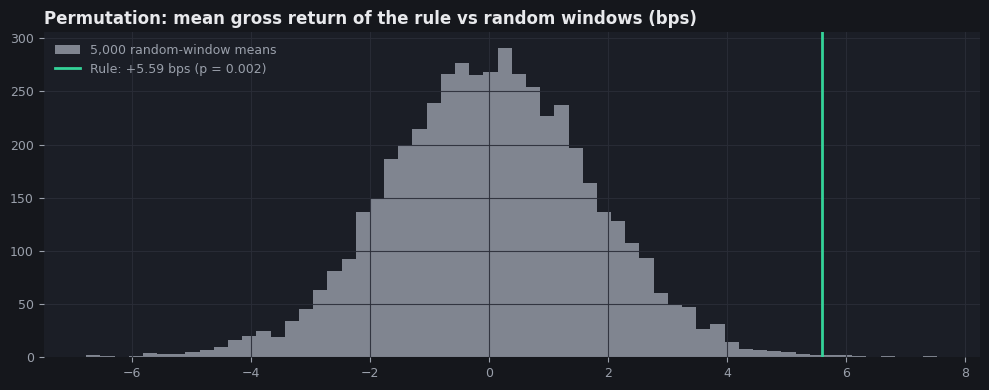


CHECKS (4.2):
   [PASS] Rule beats random windows on non-target days (p < 0.05)  ->  rule +5.59 vs control +0.02 bps | z = 3.23, p = 0.0016
   [PASS] Rule beats the same hour on non-target days (p < 0.05)  ->  rule +5.59 vs control +0.42 bps | z = 2.17, p = 0.0168


'PASS'

In [40]:
pool_any = W.loc[~W["month_end"], "gross_bps"]
perm_any  = eng.permutation_test(rule_w, pool_any, PERM_DRAWS, PERM_SEED)
perm_same = eng.permutation_test(rule_w, other_w, PERM_DRAWS, PERM_SEED)

perm_tbl = pd.DataFrame([
    {"Control group": "Random windows, any hour, non-target days (screen)", "Pool": len(pool_any), "Control mean bps": perm_any["ctrl_mean"],
     "Rule mean bps": perm_any["obs"], "z": perm_any["z"], "p": perm_any["p"]},
    {"Control group": "Same hour, non-target days", "Pool": len(other_w), "Control mean bps": perm_same["ctrl_mean"],
     "Rule mean bps": perm_same["obs"], "z": perm_same["z"], "p": perm_same["p"]}]).set_index("Control group")
print("=" * 70)
print(f"PERMUTATION TEST ({PERM_DRAWS:,} draws of n = {len(rule_w)} windows, one-sided, gross bps)")
print("=" * 70)
display(perm_tbl.round(3))

BG, PANEL, GRIDC, TXT, SUB, GREEN, RED, ORANGE = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab", "#34d399", "#f0555a", "#f5a524"
def dark_ax(ax):
    ax.set_facecolor(PANEL); ax.grid(True, color=GRIDC, lw=0.8, alpha=0.9)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(colors=SUB, labelsize=9)

fig, ax = plt.subplots(figsize=(10, 4), facecolor=BG)
dark_ax(ax)
ax.hist(perm_any["sims"], bins=60, color=SUB, alpha=0.8, label=f"{PERM_DRAWS:,} random-window means")
ax.axvline(perm_any["obs"], color=GREEN if perm_any["p"] < ALPHA else RED, lw=2, label=f"Rule: {perm_any['obs']:+.2f} bps (p = {perm_any['p']:.3f})")
ax.set_title("Permutation: mean gross return of the rule vs random windows (bps)", color=TXT, fontweight="bold", loc="left")
ax.legend(frameon=False, labelcolor=SUB, fontsize=9)
plt.tight_layout(); plt.show()

# ---- PASS / FAIL ----
print("\nCHECKS (4.2):")
check("4.2 Permutation", f"Rule beats random windows on non-target days (p < {ALPHA:g})", perm_any["p"] < ALPHA,
      f"rule {perm_any['obs']:+.2f} vs control {perm_any['ctrl_mean']:+.2f} bps | z = {perm_any['z']:.2f}, p = {perm_any['p']:.4f}")
check("4.2 Permutation", f"Rule beats the same hour on non-target days (p < {ALPHA:g})", perm_same["p"] < ALPHA,
      f"rule {perm_same['obs']:+.2f} vs control {perm_same['ctrl_mean']:+.2f} bps | z = {perm_same['z']:.2f}, p = {perm_same['p']:.4f}")

### 4.3 CONSISTENCY BY CALENDAR YEAR

RULE RESULT BY CALENDAR YEAR (bps)


,Trades,Gross mean bps,Net mean bps,Hit rate %,Net sum bps
year,,,,,
2019,12,18.00,17.00,75.00,204.05
2020,12,14.29,13.29,83.33,159.49
2021,12,2.80,1.80,50.00,21.56
2022,12,-2.29,-3.29,41.67,-39.43
2023,12,9.68,8.69,66.67,104.22
2024,12,3.62,2.62,75.00,31.40
2025,12,0.08,-0.92,33.33,-11.09
2026,10,-2.89,-3.89,50.00,-38.92


Years with a positive net mean: 5/8 (62%)


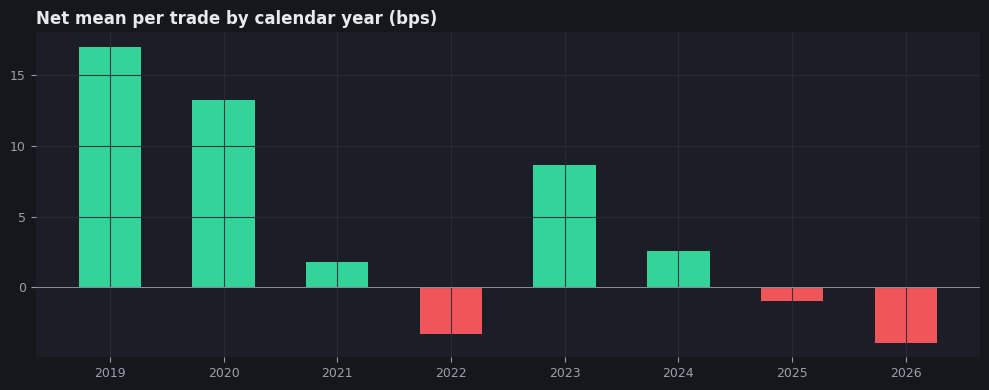


CHECKS (4.3):
   [FAIL] >= 75% of the years are profitable (net mean)  ->  5/8 years: 2019: +17.0, 2020: +13.3, 2021: +1.8, 2022: -3.3, 2023: +8.7, 2024: +2.6, 2025: -0.9, 2026: -3.9
   [FAIL] Net mean is positive in both IS and OOS  ->  IS +7.50 | OOS -0.55 bps


'FAIL'

In [41]:
yr = trades_all.assign(year=et_all.dt.year)
yr_tbl = yr.groupby("year").agg(Trades=("net_bps", "size"), gross_mean=("gross_bps", "mean"), net_mean=("net_bps", "mean"),
                                hit=("win", "mean"))
yr_tbl["hit"] *= 100
yr_tbl["net_sum"] = yr.groupby("year")["net_bps"].sum()
yr_tbl.columns = ["Trades", "Gross mean bps", "Net mean bps", "Hit rate %", "Net sum bps"]
ypos, by_year = eng.years_positive(trades_all["net_bps"], et_all)
print("=" * 70)
print("RULE RESULT BY CALENDAR YEAR (bps)")
print("=" * 70)
display(yr_tbl.round(2))
print(f"Years with a positive net mean: {int((by_year > 0).sum())}/{len(by_year)} ({ypos:.0%})")

fig, ax = plt.subplots(figsize=(10, 4), facecolor=BG)
dark_ax(ax)
ax.bar(yr_tbl.index.astype(str), yr_tbl["Net mean bps"], color=[GREEN if v > 0 else RED for v in yr_tbl["Net mean bps"]], width=0.55)
ax.axhline(0, color=SUB, lw=0.6)
ax.set_title("Net mean per trade by calendar year (bps)", color=TXT, fontweight="bold", loc="left")
plt.tight_layout(); plt.show()

# ---- PASS / FAIL ----
print("\nCHECKS (4.3):")
check("4.3 Years", f">= {YEARS_POS_MIN:.0%} of the years are profitable (net mean)", ypos >= YEARS_POS_MIN,
      f"{int((by_year > 0).sum())}/{len(by_year)} years: " + ", ".join(f"{y}: {v:+.1f}" for y, v in by_year.items()))
check("4.3 Years", "Net mean is positive in both IS and OOS",
      trades_is["net_bps"].mean() > 0 and trades_oos["net_bps"].mean() > 0,
      f"IS {trades_is['net_bps'].mean():+.2f} | OOS {trades_oos['net_bps'].mean():+.2f} bps")

### 4.4 CONCENTRATION: IS THE EDGE CARRIED BY A FEW TRADES?

CONCENTRATION: NET RESULT WITHOUT THE BEST 10% OF TRADES (10 trades)


,Net mean bps,Median bps,Trades
All trades,4.588,5.440,94
Without the best 10%,-0.561,2.569,84


The best 10 trades make 111% of the total net result


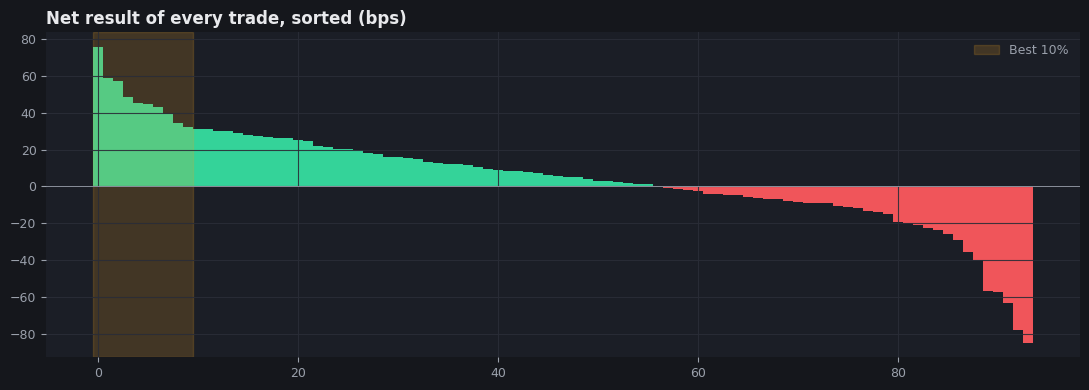


CHECKS (4.4):
   [FAIL] Net mean stays > 0 without the best 10% of trades  ->  -0.56 bps without 10 trades (all: +4.59 bps)


'FAIL'

In [42]:
net = trades_all["net_bps"].to_numpy()
srt = np.sort(net)[::-1]
n_best = int(len(net) - int(len(net) * (1.0 - TRIM_SHARE)))              # trades removed by drop_best
trim_mean = eng.drop_best(net, TRIM_SHARE)
share_best = srt[:n_best].sum() / net.sum() if net.sum() > 0 else np.nan
conc_tbl = pd.DataFrame({"Net mean bps": [net.mean(), trim_mean], "Median bps": [np.median(net), np.median(np.sort(net)[:len(net) - n_best])],
                         "Trades": [len(net), len(net) - n_best]}, index=["All trades", f"Without the best {TRIM_SHARE:.0%}"])
print("=" * 70)
print(f"CONCENTRATION: NET RESULT WITHOUT THE BEST {TRIM_SHARE:.0%} OF TRADES ({n_best} trades)")
print("=" * 70)
display(conc_tbl.round(3))
print(f"The best {n_best} trades make {share_best:.0%} of the total net result" if not np.isnan(share_best) else "Total net result is not positive")

fig, ax = plt.subplots(figsize=(11, 4), facecolor=BG)
dark_ax(ax)
ax.bar(range(len(net)), np.sort(net)[::-1], color=[RED if v <= 0 else GREEN for v in np.sort(net)[::-1]], width=1.0)
ax.axvspan(-0.5, n_best - 0.5, color=ORANGE, alpha=0.18, label=f"Best {TRIM_SHARE:.0%}")
ax.axhline(0, color=SUB, lw=0.6)
ax.set_title("Net result of every trade, sorted (bps)", color=TXT, fontweight="bold", loc="left")
ax.legend(frameon=False, labelcolor=SUB, fontsize=9)
plt.tight_layout(); plt.show()

# ---- PASS / FAIL ----
print("\nCHECKS (4.4):")
check("4.4 Concentration", f"Net mean stays > 0 without the best {TRIM_SHARE:.0%} of trades", trim_mean > 0,
      f"{trim_mean:+.2f} bps without {n_best} trades (all: {net.mean():+.2f} bps)")

## 5. BASELINE BACKTEST WITH FROZEN RULES

PERFORMANCE SUMMARY (NET OF 0.5 BPS PER SIDE · daily MTM drawdown, Sharpe annualised x252)


,Period,Sizing,Trades,Win Rate,Profit Factor,Net mean,t,Total Return,Sharpe,Max Drawdown
0,In-Sample (2019-2023),100% Capital,60,63.3%,1.956,+7.50 bps,2.02,4.57%,0.79,-0.96%
1,In-Sample (2019-2023),1x Capital (ideal),60,63.3%,1.956,+7.50 bps,2.02,4.57%,0.79,-0.96%
2,Out-of-Sample (2024-2026),100% Capital,34,52.9%,0.932,-0.55 bps,-0.13,-0.20%,-0.07,-1.30%
3,Out-of-Sample (2024-2026),1x Capital (ideal),34,52.9%,0.932,-0.55 bps,-0.13,-0.20%,-0.07,-1.30%
4,Full Period (2019-2026),100% Capital,94,59.6%,1.579,+4.59 bps,1.63,4.37%,0.52,-1.30%
5,Full Period (2019-2026),1x Capital (ideal),94,59.6%,1.579,+4.59 bps,1.63,4.37%,0.52,-1.30%


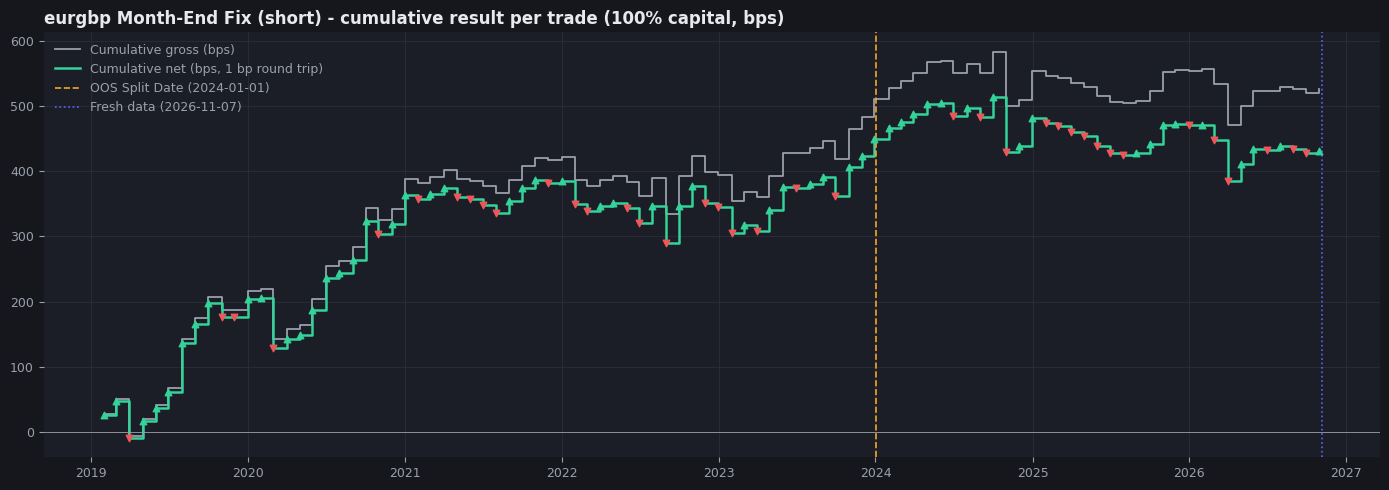

Time in market: 0.769% | trades per year: 12.0

CHECKS (5):
   [PASS] Profit Factor, full period >= 1.3  ->  PF = 1.579
   [PASS] Profit Factor, IS >= 1.3  ->  PF = 1.956
   [FAIL] Profit Factor, OOS >= 1.3  ->  PF = 0.932
   [FAIL] OOS does not decay vs IS (decay < 50%)  ->  IS +7.50 -> OOS -0.55 bps (decay 107%)
   [FAIL] t-stat of the mean net trade >= 2  ->  t = 1.63
   [FAIL] t-stat >= 2.75 (corrected for k = 17 tests)  ->  t = 1.63
   [PASS] Trades, OOS >= 30  ->  34 trades
   [FAIL] t-stat OOS >= 1.645  ->  t OOS = -0.13
   [FAIL] Expectancy > 0 in IS and OOS (net of costs)  ->  IS +7.50 | OOS -0.55 bps


'FAIL'

In [43]:
def sized(t, sizing):
    return t if sizing == "capital" else t.assign(pnl=t["pnl_frac"], win=t["pnl_frac"] > 0)

def perf_row(t, price_df, period, sizing):
    m = compute_metrics(sized(t, sizing), contract_multiplier=1.0, cost_per_trade=0.0)
    ret = eng.daily_returns(price_df, t, sizing=sizing)
    eq = (1.0 + ret).cumprod()
    return {"Period": period, "Sizing": "100% Capital" if sizing == "capital" else f"{SIZE_FRAC:g}x Capital (ideal)",
            "Trades": m["num_trades"], "Win Rate": f"{m['win_rate']:.1f}%", "Profit Factor": f"{m['profit_factor']:.3f}",
            "Net mean": f"{t['net_bps'].mean():+.2f} bps", "t": f"{eng.tstat(t['net_bps']):.2f}",
            "Total Return": f"{(eq.iloc[-1] - 1) * 100:.2f}%", "Sharpe": f"{sharpe_ratio(ret, periods_per_year=PPY):.2f}",
            "Max Drawdown": f"{max_drawdown(eq) * 100:.2f}%"}

periods = [(f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", trades_is, df_is),
           (f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", trades_oos, df_oos),
           (f"Full Period ({df.index[0].year}-{df.index[-1].year})", trades_all, df)]
perf_table = pd.DataFrame([perf_row(t, d, name, s) for name, t, d in periods for s in ("capital", "fraction")])

print("=" * 80)
print(f"PERFORMANCE SUMMARY (NET OF {COST_BPS:g} BPS PER SIDE · daily MTM drawdown, Sharpe annualised x{PPY})")
print("=" * 80)
display(perf_table)

cum = pd.DataFrame({"gross": trades_all["gross_bps"].cumsum().to_numpy(), "net": trades_all["net_bps"].cumsum().to_numpy()}, index=et_all)
fig, ax = plt.subplots(figsize=(14, 5), facecolor=BG)
dark_ax(ax)
ax.step(cum.index, cum["gross"], where="post", color=SUB, lw=1.3, label="Cumulative gross (bps)")
ax.step(cum.index, cum["net"], where="post", color=GREEN, lw=1.8, label=f"Cumulative net (bps, {SPREAD_BPS:g} bp round trip)")
won = trades_all["net_bps"].to_numpy() > 0
ax.scatter(cum.index[won], cum["net"][won], marker="^", s=22, color=GREEN, zorder=3)
ax.scatter(cum.index[~won], cum["net"][~won], marker="v", s=22, color=RED, zorder=3)
ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2, label=f"OOS Split Date ({oos_start:%Y-%m-%d})")
if FRESH_START is not None:
    ax.axvline(FRESH_START, color="#5468ff", ls=":", lw=1.2, label=f"Fresh data ({FRESH_START:%Y-%m-%d})")
ax.axhline(0, color=SUB, lw=0.6)
ax.set_title(f"{TICKER} Month-End Fix ({SIDE}) - cumulative result per trade (100% capital, bps)", color=TXT, fontweight="bold", loc="left")
ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

in_market = float(trades_all["bars"].sum()) / len(df)
print(f"Time in market: {in_market * 100:.3f}% | trades per year: {len(trades_all) / ((df.index[-1] - df.index[0]).days / 365.25):.1f}")

# ---- PASS / FAIL ----
print("\nCHECKS (5):")
net_is, net_oos, net_all = (t["net_bps"].to_numpy() for t in (trades_is, trades_oos, trades_all))
pf_is, pf_oos, pf_all = (eng.profit_factor(x) for x in (net_is, net_oos, net_all))
t_all, t_oos = eng.tstat(net_all), eng.tstat(net_oos)
decay = 1.0 - net_oos.mean() / net_is.mean() if net_is.mean() > 0 else np.nan
check("5. Baseline", f"Profit Factor, full period >= {PF_MIN:g}", pf_all >= PF_MIN, f"PF = {pf_all:.3f}")
check("5. Baseline", f"Profit Factor, IS >= {PF_MIN:g}", pf_is >= PF_MIN, f"PF = {pf_is:.3f}")
check("5. Baseline", f"Profit Factor, OOS >= {PF_MIN:g}", pf_oos >= PF_MIN, f"PF = {pf_oos:.3f}")
check("5. Baseline", f"OOS does not decay vs IS (decay < {DECAY_MAX:.0%})", np.isnan(decay) or decay < DECAY_MAX,
      f"IS {net_is.mean():+.2f} -> OOS {net_oos.mean():+.2f} bps" + (f" (decay {decay:.0%})" if not np.isnan(decay) else " (IS mean <= 0: decay not defined)"))
check("5. Baseline", f"t-stat of the mean net trade >= {T_MIN:g}", t_all >= T_MIN, f"t = {t_all:.2f}")
check("5. Baseline", f"t-stat >= {T_CORR:.2f} (corrected for k = {K_TESTS} tests)", t_all >= T_CORR, f"t = {t_all:.2f}")
check("5. Baseline", f"Trades, OOS >= {N_OOS_MIN}", len(net_oos) >= N_OOS_MIN, f"{len(net_oos)} trades")
check("5. Baseline", f"t-stat OOS >= {T_OOS_MIN:g}", t_oos >= T_OOS_MIN, f"t OOS = {t_oos:.2f}")
check("5. Baseline", "Expectancy > 0 in IS and OOS (net of costs)", net_is.mean() > 0 and net_oos.mean() > 0,
      f"IS {net_is.mean():+.2f} | OOS {net_oos.mean():+.2f} bps")

## 5.1 MINIMUM-LOT SIZING AND HARD LIMIT (CFD)

The robot can only trade whole lots. With 1 lot = 100,000 EUR, the **minimum lot (0.01)** is about 1,000 EUR of notional: on 1,000-2,000 of capital that is already ~1x, so the real sizing is the minimum lot, not a target fraction. The drawdown is measured **intrabar** (candle highs, since the rule is short).

HARD LIMIT -9% · MINIMUM-LOT SIZING (lot 0.01, contract 100,000, account currency)


,Sizing,Notional / capital,Total Return,Profit,Max DD (intrabar),Max DD (closes),Headroom,Hard limit
0,1x ideal fraction,1.00x,4.37%,-,-1.384%,-1.306%,+7.62 pts,PASS
1,"Min lot 0.01 (capital 1,000)",1.12x,5.11%,+51.10,-1.447%,-1.363%,+7.55 pts,PASS
2,"Min lot 0.01 (capital 2,000)",0.56x,2.55%,+51.07,-0.746%,-0.702%,+8.25 pts,PASS


Notional of the minimum lot at 0.8343: 1,084 (account currency) | minimum capital for the minimum lot to weigh <= 1x: 1,085
Average result per trade at the minimum lot: +0.543 (account currency) -> a month-end trade is small money at this size: it only pays as a diversifier

CHECKS (5.1):
   [PASS] 1x ideal fraction stays inside -9% (intrabar)  ->  max DD -1.38% | headroom +7.62 pts
   [PASS] Minimum lot on 1,000 stays inside -9% (intrabar)  ->  max DD -1.45% (closes only -1.36%) | headroom +7.55 pts
   [PASS] Minimum lot on 2,000 stays inside -9% (intrabar)  ->  max DD -0.75% (closes only -0.70%) | headroom +8.25 pts
   [PASS] Every trade is executable with the minimum lot  ->  94 of 94 trades taken on every capital


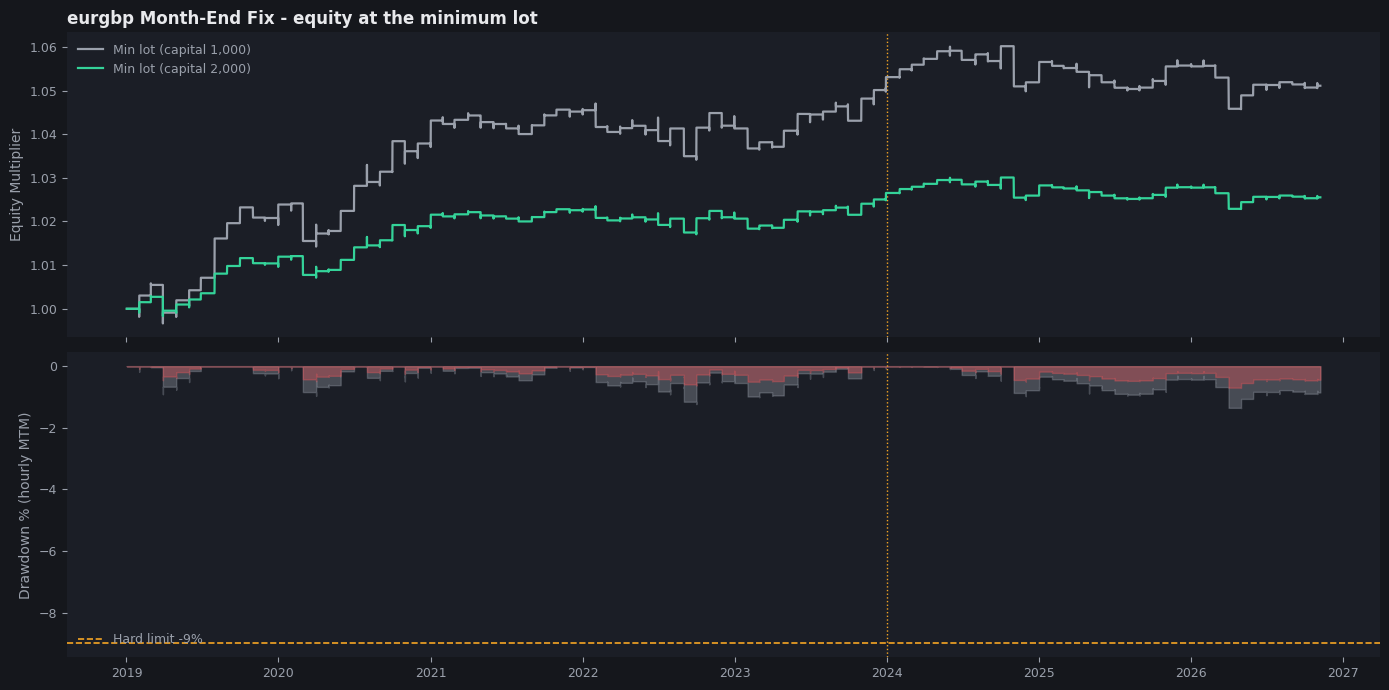

In [44]:
last_price = float(df["close"].iloc[-1])
min_capital = eng.min_capital_for_target(last_price, SIZE_FRAC)

def limit_row(label, sizing, extra=None):
    hr = eng.hourly_returns(df, trades_all, sizing=sizing)
    rep = eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, sizing=sizing)
    row = {"Sizing": label, "Total Return": f"{((1.0 + hr).prod() - 1.0) * 100:.2f}%",
           "Max DD (intrabar)": f"{rep['max_dd'] * 100:.3f}%", "Max DD (closes)": f"{rep['max_dd_close'] * 100:.3f}%",
           "Headroom": f"{rep['headroom'] * 100:+.2f} pts", "Hard limit": "PASS" if rep["passed"] else "FAIL"}
    return {**row, **(extra or {})}, rep, hr

rows, REPORTS, HOURLY, LOTS = [], {}, {}, {}
r0, rep0, hr0 = limit_row(f"{SIZE_FRAC:g}x ideal fraction", "fraction", {"Notional / capital": f"{SIZE_FRAC:.2f}x", "Profit": "-"})
rows.append(r0)
for cap in CAPITALS:
    LOTS[cap] = eng.cfd_trade_sizes(trades_all, cap, lots=MIN_LOT)
    sz = LOTS[cap]["size_fraction"].to_numpy()
    r, REPORTS[cap], HOURLY[cap] = limit_row(f"Min lot {MIN_LOT:g} (capital {cap:,.0f})", sz,
                                             {"Notional / capital": f"{LOTS[cap]['notional'].mean() / cap:.2f}x"})
    r["Profit"] = f"{cap * ((1.0 + HOURLY[cap]).prod() - 1.0):+,.2f}"
    rows.append(r)
limit_table = pd.DataFrame(rows)[["Sizing", "Notional / capital", "Total Return", "Profit", "Max DD (intrabar)", "Max DD (closes)", "Headroom", "Hard limit"]]

print("=" * 80)
print(f"HARD LIMIT -{HARD_LIMIT:.0%} · MINIMUM-LOT SIZING (lot {MIN_LOT:g}, contract {CONTRACT_SIZE:,.0f}, account currency)")
print("=" * 80)
display(limit_table)
print(f"Notional of the minimum lot at {last_price:.4f}: {LOTS[CAP_MAIN]['notional'].iloc[-1]:,.0f} (account currency) | "
      f"minimum capital for the minimum lot to weigh <= {SIZE_FRAC:g}x: {min_capital:,.0f}")
print(f"Average result per trade at the minimum lot: {np.mean([cap * ((1.0 + HOURLY[cap]).prod() - 1.0) for cap in CAPITALS]) / len(trades_all):+.3f} "
      f"(account currency) -> a month-end trade is small money at this size: it only pays as a diversifier")

# ---- PASS / FAIL ----
print("\nCHECKS (5.1):")
check("5.1 Hard limit", f"{SIZE_FRAC:g}x ideal fraction stays inside -{HARD_LIMIT:.0%} (intrabar)", rep0["passed"],
      f"max DD {rep0['max_dd'] * 100:.2f}% | headroom {rep0['headroom'] * 100:+.2f} pts")
for cap in CAPITALS:
    check("5.1 Hard limit", f"Minimum lot on {cap:,.0f} stays inside -{HARD_LIMIT:.0%} (intrabar)", REPORTS[cap]["passed"],
          f"max DD {REPORTS[cap]['max_dd'] * 100:.2f}% (closes only {REPORTS[cap]['max_dd_close'] * 100:.2f}%) | headroom {REPORTS[cap]['headroom'] * 100:+.2f} pts")
check("5.1 Hard limit", "Every trade is executable with the minimum lot", all(int(LOTS[cap]["taken"].sum()) == len(trades_all) for cap in CAPITALS),
      f"{len(trades_all)} of {len(trades_all)} trades taken on every capital")

dd_series = {cap: (lambda e: e / np.maximum(e.cummax(), 1.0) - 1.0)((1.0 + HOURLY[cap]).cumprod()) for cap in CAPITALS}
fig, (ax_eq, ax_dd) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, facecolor=BG)
for ax in (ax_eq, ax_dd):
    dark_ax(ax); ax.grid(False); ax.axvline(oos_start, color=ORANGE, ls=":", lw=1.0)
for cap, col in zip(CAPITALS, (SUB, GREEN)):
    ax_eq.plot(HOURLY[cap].index, (1.0 + HOURLY[cap]).cumprod(), color=col, lw=1.6, label=f"Min lot (capital {cap:,.0f})")
    ax_dd.fill_between(dd_series[cap].index, dd_series[cap] * 100, 0, color=RED if cap == CAP_MAIN else SUB, alpha=0.35)
ax_eq.set_title(f"{TICKER} Month-End Fix - equity at the minimum lot", color=TXT, fontweight="bold", loc="left")
ax_eq.set_ylabel("Equity Multiplier", color=SUB)
ax_eq.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
ax_dd.axhline(-HARD_LIMIT * 100, color=ORANGE, ls="--", lw=1.2, label=f"Hard limit -{HARD_LIMIT:.0%}")
ax_dd.set_ylabel("Drawdown % (hourly MTM)", color=SUB)
ax_dd.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

## 5.2 ANNUAL RETURNS AND HARD LIMIT CHECK

ANNUAL RETURNS · MIN LOT ON 2,000 · HARD LIMIT -9% · * = partial year


,year,ret,mdd,n_trades,partial,breach
0,2019,+1.19%,-0.46%,12,False,False
1,2020,+0.95%,-0.49%,12,False,False
2,2021,+0.12%,-0.23%,12,False,False
3,2022,-0.20%,-0.63%,12,False,False
4,2023,+0.58%,-0.24%,12,False,False
5,2024,+0.17%,-0.50%,12,False,False
6,2025,-0.05%,-0.33%,12,False,False
7,2026,-0.22%,-0.54%,10,True,False


Steps below the limit: 0 | first breach: None

CHECKS (5.2):
   [PASS] No calendar year breaches the hard limit  ->  years in breach: none | worst year DD -0.63%


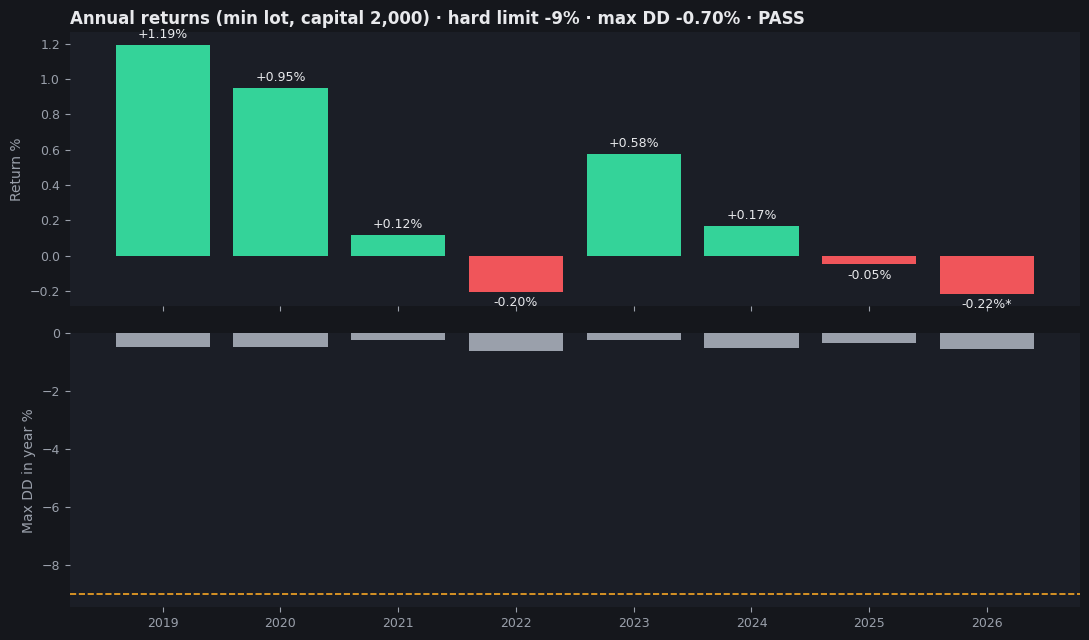

In [45]:
def plot_annual_returns(annual, report, hard_limit):
    fig, (ax_ret, ax_dd) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, facecolor=BG)
    years = annual["year"].astype(str).to_numpy()
    bars = ax_ret.bar(years, annual["ret"] * 100, color=[GREEN if v >= 0 else RED for v in annual["ret"]])
    ax_dd.bar(years, annual["mdd"] * 100, color=[RED if b else SUB for b in annual["breach"]])
    ax_dd.axhline(-hard_limit * 100, color=ORANGE, ls="--", lw=1.2)
    for ax in (ax_ret, ax_dd):
        dark_ax(ax); ax.grid(False)
    for rect, value, partial in zip(bars, annual["ret"], annual["partial"]):
        ax_ret.annotate(f"{value:+.2%}" + ("*" if partial else ""), (rect.get_x() + rect.get_width() / 2, value * 100),
                        xytext=(0, 3 if value >= 0 else -3), textcoords="offset points",
                        ha="center", va="bottom" if value >= 0 else "top", color=TXT, fontsize=9)
    status = "PASS" if report["passed"] else "FAIL"
    ax_ret.set_title(f"Annual returns (min lot, capital {CAP_MAIN:,.0f}) · hard limit -{hard_limit:.0%} · max DD {report['max_dd']:.2%} · {status}",
                     color=TXT, fontweight="bold", loc="left")
    ax_ret.set_ylabel("Return %", color=SUB)
    ax_dd.set_ylabel("Max DD in year %", color=SUB)
    plt.tight_layout(); plt.show()

hourly_lot = HOURLY[CAP_MAIN]
annual = eng.annual_returns(hourly_lot, trades_all, HARD_LIMIT)
report_annual = eng.hard_limit_report(hourly_lot, HARD_LIMIT)

print("=" * 80)
print(f"ANNUAL RETURNS · MIN LOT ON {CAP_MAIN:,.0f} · HARD LIMIT -{HARD_LIMIT:.0%} · * = partial year")
print("=" * 80)
display(annual.style.format({"ret": "{:+.2%}", "mdd": "{:.2%}"}))
print(f"Steps below the limit: {report_annual['steps_in_breach']} | first breach: {report_annual['first_breach']}")

# ---- PASS / FAIL ----
print("\nCHECKS (5.2):")
breach_years = annual.loc[annual["breach"], "year"].astype(int).tolist()
check("5.2 Annual", "No calendar year breaches the hard limit", not annual["breach"].any(),
      f"years in breach: {breach_years if breach_years else 'none'} | worst year DD {annual['mdd'].min() * 100:.2f}%")
plot_annual_returns(annual, report_annual, HARD_LIMIT)

## 5.3 FRESH DATA (CANDLES AFTER THE FREEZE)

The only evidence that is independent of the screening. The rule is not touched: the trades after `split.fresh_start` are simply counted and tested. With ~12 trades a year, **n >= 36 needs about three years**.

In [46]:
if FRESH_START is None:
    fresh = trades_all.iloc[0:0]
    print("No split.fresh_start in the YAML: nothing to evaluate.")
else:
    fresh = trades_all[et_all.to_numpy() >= np.datetime64(FRESH_START)]
N_FRESH_NEEDED = 36
n_fr = len(fresh)
print("=" * 70)
print(f"FRESH DATA (from {FRESH_START:%Y-%m-%d})" if FRESH_START is not None else "FRESH DATA")
print("=" * 70)
print(f"Fresh trades: {n_fr} of the {N_FRESH_NEEDED} needed (n >= {N_FRESH_NEEDED}, t >= {T_OOS_MIN:g})")
if n_fr >= 3:
    print(f"Net mean {fresh['net_bps'].mean():+.2f} bps | t = {eng.tstat(fresh['net_bps']):.2f} | gross {fresh['gross_bps'].mean():+.2f} bps")

# ---- PASS / FAIL ----
print("\nCHECKS (5.3):")
if n_fr < N_FRESH_NEEDED:
    check("5.3 Fresh data", f"Fresh data: n >= {N_FRESH_NEEDED} and t >= {T_OOS_MIN:g}", None,
          f"only {n_fr} trades since the freeze: not enough to say anything yet")
else:
    check("5.3 Fresh data", f"Fresh data: n >= {N_FRESH_NEEDED} and t >= {T_OOS_MIN:g}", eng.tstat(fresh["net_bps"]) >= T_OOS_MIN,
          f"n = {n_fr} | t = {eng.tstat(fresh['net_bps']):.2f} | net {fresh['net_bps'].mean():+.2f} bps")

FRESH DATA (from 2026-11-07)
Fresh trades: 0 of the 36 needed (n >= 36, t >= 1.645)

CHECKS (5.3):
   [SKIP] Fresh data: n >= 36 and t >= 1.645  ->  only 0 trades since the freeze: not enough to say anything yet


## 6. SANITY CHECKS & VERIFICATION

In [47]:
print("=" * 70)
print("SANITY CHECKS & REPRODUCIBILITY")
print("=" * 70)

# 1. Calendar, execution model and costs (violations are collected, not asserted, so the notebook keeps running)
cost = COST_BPS / 1e4
month_end_set = set(eng.month_end_days(df["local_date"].min(), df["local_date"].max()))
violations, prev_end = [], None
for idx_, r in trades_all.iterrows():
    et, xt = pd.Timestamp(r["entry_time"]), pd.Timestamp(r["exit_time"])
    ldn_e = et.tz_localize("UTC").tz_convert("Europe/London")
    ldn_x = xt.tz_localize("UTC").tz_convert("Europe/London")
    if not (ldn_e.hour == ENTRY_H and ldn_e.minute == 0):
        violations.append(f"trade {idx_}: entry is not {ENTRY_H}:00 London")
    if ldn_e.tz_localize(None).normalize() not in month_end_set or ldn_e.dayofweek >= 5:
        violations.append(f"trade {idx_}: entry is not on the last business day of the month")
    if not (xt - et == HOLD * eng.H1 and ldn_x.hour == EXIT_H and ldn_x.date() == ldn_e.date()):
        violations.append(f"trade {idx_}: exit is not {EXIT_H}:00 London the same day ({HOLD} h hold)")
    if not (df.index[int(r["i_ent"])] == et and df.index[int(r["i_sal"])] == xt):
        violations.append(f"trade {idx_}: i_ent / i_sal misaligned")
    if not (np.isclose(r["entry_price"], df.loc[et, "open"] * (1 + SIGN * cost), atol=1e-9)
            and np.isclose(r["exit_price"], df.loc[xt, "open"] * (1 - SIGN * cost), atol=1e-9)):
        violations.append(f"trade {idx_}: entry / exit price mismatch (BID model)")
    if r["type"] != SIDE:
        violations.append(f"trade {idx_}: wrong direction")
    if prev_end is not None and et < prev_end:
        violations.append(f"trade {idx_}: overlaps the previous trade")
    prev_end = xt
print(f"Sanity Check 1: {SIDE} at the OPEN of {ENTRY_H:02d}:00 London, cover at the OPEN of {EXIT_H:02d}:00, last business day, no overlap ({len(trades_all)} trades).")
print(f"   - The rule is a calendar rule: no signal, no lookahead.")
print(f"   - Execution at the open: entry x(1{'-' if SIGN < 0 else '+'}{COST_BPS:g} bps), exit x(1{'+' if SIGN < 0 else '-'}{COST_BPS:g} bps).")
check("6. Sanity", "Calendar, direction, execution model and costs respected on every trade", not violations,
      f"{len(trades_all)} trades checked" + (f" | {len(violations)} violations, first: {violations[0]}" if violations else ""))

# 2. Intraday: no overnight, no swap
print(f"\nSanity Check 2: overnight rollovers crossed (22:00 UTC): {int(trades_all['nights'].sum())}.")
check("6. Sanity", "No trade crosses the rollover (0 nights, swap does not apply)", int(trades_all["nights"].sum()) == 0,
      f"{int(trades_all['nights'].sum())} nights over {len(trades_all)} trades")

# 3. DST: 12:00 London must be 11:00 UTC (BST) or 12:00 UTC (GMT)
utc_h = et_all.dt.hour.value_counts().sort_index()
print(f"\nSanity Check 3: UTC hour of the entry (London 12:00 = 11 UTC in summer, 12 UTC in winter): {utc_h.to_dict()}")
check("6. Sanity", "Entry UTC hour is 11 (BST) or 12 (GMT) on every trade", set(utc_h.index) <= {11, 12}, f"{utc_h.to_dict()}")

# 4. Trade distribution per calendar year (full years only)
tpy = et_all.dt.year.value_counts().sort_index()
full_years = [y for y in range(df.index[0].year, df.index[-1].year + 1)
              if pd.Timestamp(f"{y}-01-01") >= df.index[0] and pd.Timestamp(f"{y}-12-31") <= df.index[-1]]
tpy_full = tpy.reindex(full_years, fill_value=0)
print("\nSanity Check 4: Trade Frequency per Year:")
print(f"   - Average trades per year: {tpy.mean():.1f}")
print(f"   - Min trades (full years): {tpy_full.min()} ({tpy_full.idxmin()}) | Max trades: {tpy.max()} ({tpy.idxmax()})")
check("6. Sanity", f"Every full calendar year has >= {MIN_TRADES_PER_YEAR} trades", (tpy_full >= MIN_TRADES_PER_YEAR).all(),
      f"min {tpy_full.min()} ({tpy_full.idxmin()}) | max {tpy_full.max()} ({tpy_full.idxmax()}) over {len(tpy_full)} full years")

# 5. MTM paths reproduce the trade returns exactly (short and long)
paths = eng.trade_mtm_paths(df, trades_all, sizing="capital")
err = max(abs(np.prod(1 + p) - (1 + pnl / 100)) for p, pnl in zip(paths, trades_all["pnl"]))
print(f"\nSanity Check 5: MTM paths telescope to trade returns (max abs error {err:.2e}).")
check("6. Sanity", "MTM paths telescope to the trade returns (error < 1e-9)", err < 1e-9, f"max abs error {err:.2e}")

# 6. Reconciliation with the screening (informational: same rule, same broker candles, measured spread instead of 1 bp)
REF = {"trades_per_year": 118 / 9.85, "net_bps": 5.0, "t": 2.07}
tpy_ours = len(trades_all) / ((df.index[-1] - df.index[0]).days / 365.25)
print("\nSanity Check 6: Comparison with the screening reference (informational, not a gate):")
display(pd.DataFrame([{"Metric": "Trades per year", "Pipeline": f"{tpy_ours:.1f}", "Screening": f"{REF['trades_per_year']:.1f}"},
                      {"Metric": "Net mean bps", "Pipeline": f"{net_all.mean():+.2f}", "Screening": f"{REF['net_bps']:+.2f}"},
                      {"Metric": "t net", "Pipeline": f"{t_all:.2f}", "Screening": f"{REF['t']:.2f}"}]).set_index("Metric"))
check("6. Reference (info)", "Trades per year match the screening (±15%)", abs(tpy_ours / REF["trades_per_year"] - 1) <= 0.15,
      f"{tpy_ours:.1f} vs {REF['trades_per_year']:.1f}")
check("6. Reference (info)", "Net mean matches the screening (±2 bps; the cost model differs)", abs(net_all.mean() - REF["net_bps"]) <= 2.0,
      f"{net_all.mean():+.2f} vs {REF['net_bps']:+.2f} bps")

SANITY CHECKS & REPRODUCIBILITY
Sanity Check 1: short at the OPEN of 12:00 London, cover at the OPEN of 16:00, last business day, no overlap (94 trades).
   - The rule is a calendar rule: no signal, no lookahead.
   - Execution at the open: entry x(1-0.5 bps), exit x(1+0.5 bps).
   [PASS] Calendar, direction, execution model and costs respected on every trade  ->  94 trades checked

Sanity Check 2: overnight rollovers crossed (22:00 UTC): 0.
   [PASS] No trade crosses the rollover (0 nights, swap does not apply)  ->  0 nights over 94 trades

Sanity Check 3: UTC hour of the entry (London 12:00 = 11 UTC in summer, 12 UTC in winter): {11: 55, 12: 39}
   [PASS] Entry UTC hour is 11 (BST) or 12 (GMT) on every trade  ->  {11: 55, 12: 39}

Sanity Check 4: Trade Frequency per Year:
   - Average trades per year: 11.8
   - Min trades (full years): 12 (2020) | Max trades: 12 (2019)
   [PASS] Every full calendar year has >= 10 trades  ->  min 12 (2020) | max 12 (2020) over 6 full years

Sanity Che

,Pipeline,Screening
Metric,,
Trades per year,12.0,12.0
Net mean bps,+4.59,+5.00
t net,1.63,2.07


   [PASS] Trades per year match the screening (±15%)  ->  12.0 vs 12.0
   [PASS] Net mean matches the screening (±2 bps; the cost model differs)  ->  +4.59 vs +5.00 bps


'PASS'

## 7. CONTROL GROUP: THE RULE VS THE NAKED WINDOW (SAME BARS, SAME COSTS, SAME SIZE)

VARIANT COMPARISON (1x capital per trade, 0.5 bps/side)


,Variant,Trades,Net mean bps,t,Profit Factor,Sharpe,Max Drawdown,Final Capital
0,Naked window (every business day),2038,-0.34,-0.67,0.959,-0.21,-15.09%,0.928x
1,Rule (last business day of the month),94,+4.59,1.63,1.579,0.52,-1.30%,1.044x



CHECKS (7):
   [PASS] Rule net mean beats the naked window  ->  rule +4.59 | naked -0.34 bps
   [PASS] Rule Profit Factor beats the naked window  ->  rule 1.579 | naked 0.959
   [PASS] Rule t-stat beats the naked window  ->  rule 1.63 | naked -0.67


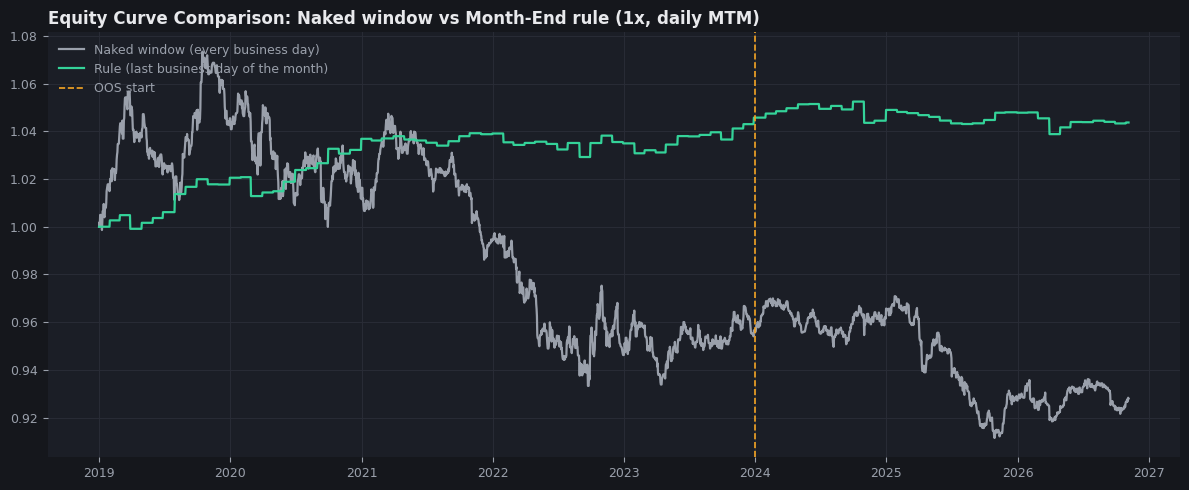

In [48]:
v_naked = eng.run_fix_backtest(df, universe="every_day", **RULES)
variants = {"Naked window (every business day)": v_naked, "Rule (last business day of the month)": trades_all}

rows, curves, raw = [], {}, {}
for name, t in variants.items():
    r = eng.daily_returns(df, t, sizing="fraction")
    eq = (1 + r).cumprod()
    curves[name] = eq
    raw[name] = {"pf": eng.profit_factor(t["net_bps"]), "mean": t["net_bps"].mean(), "t": eng.tstat(t["net_bps"]),
                 "sharpe": sharpe_ratio(r, periods_per_year=PPY), "mdd": max_drawdown(eq), "final": float(eq.iloc[-1])}
    rows.append({"Variant": name, "Trades": len(t), "Net mean bps": f"{raw[name]['mean']:+.2f}", "t": f"{raw[name]['t']:.2f}",
                 "Profit Factor": f"{raw[name]['pf']:.3f}", "Sharpe": f"{raw[name]['sharpe']:.2f}",
                 "Max Drawdown": f"{raw[name]['mdd'] * 100:.2f}%", "Final Capital": f"{eq.iloc[-1]:.3f}x"})
print("=" * 80)
print(f"VARIANT COMPARISON ({SIZE_FRAC:g}x capital per trade, {COST_BPS:g} bps/side)")
print("=" * 80)
display(pd.DataFrame(rows))

# ---- PASS / FAIL ----
print("\nCHECKS (7):")
k_naked, k_rule = list(variants)
check("7. Variants", "Rule net mean beats the naked window", raw[k_rule]["mean"] > raw[k_naked]["mean"],
      f"rule {raw[k_rule]['mean']:+.2f} | naked {raw[k_naked]['mean']:+.2f} bps")
check("7. Variants", "Rule Profit Factor beats the naked window", raw[k_rule]["pf"] > raw[k_naked]["pf"],
      f"rule {raw[k_rule]['pf']:.3f} | naked {raw[k_naked]['pf']:.3f}")
check("7. Variants", "Rule t-stat beats the naked window", raw[k_rule]["t"] > raw[k_naked]["t"],
      f"rule {raw[k_rule]['t']:.2f} | naked {raw[k_naked]['t']:.2f}")

fig, ax = plt.subplots(figsize=(12, 5), facecolor=BG)
dark_ax(ax)
for (name, eq), col in zip(curves.items(), (SUB, GREEN)):
    ax.plot(eq.index, eq, color=col, lw=1.6, label=name)
ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2, label="OOS start")
ax.set_title("Equity Curve Comparison: Naked window vs Month-End rule (1x, daily MTM)", color=TXT, fontweight="bold", loc="left")
ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

## 8. THE SCREEN: SUMMARY OF HYPOTHESIS & VERDICT (PASA / CASI / STOP)

In [49]:
# ---- Gate inputs ----
trim_mean = eng.drop_best(net_all, TRIM_SHARE)
edge_x = trades_all["gross_bps"].mean() / SPREAD_BPS
dd_worst = min(REPORTS[c]["max_dd"] for c in CAPITALS)            # worst intrabar DD over the target capitals, min lot
ypos, _ = eng.years_positive(net_all, et_all)

# Correlation of daily returns with the other edges (needs their CSV of trades; PENDING until it exists)
def load_other_trades(path):
    raw = eng._read_csv_any_sep(eng._find_csv(path))
    raw.columns = [str(c).strip().lower() for c in raw.columns]
    tcol = next(c for c in ("exit_time", "close_time", "entry_time", "time") if c in raw.columns)
    pcol = next(c for c in ("pnl_frac", "pnl", "ret", "return", "profit") if c in raw.columns)
    return pd.DataFrame({"when": pd.to_datetime(raw[tcol], utc=True).dt.tz_convert(None), "pnl": raw[pcol].astype(float)})

corr_g, corr_note = None, "no CSV of trades yet (correlation.gotobi_trades_csv is null)"
gotobi_csv = (cfg.get("correlation") or {}).get("gotobi_trades_csv")
if gotobi_csv:
    try:
        corr_val, n_days, n_both = eng.return_correlation(eng.daily_trade_pnl(trades_all, "pnl_frac"),
                                                          eng.daily_trade_pnl(load_other_trades(gotobi_csv), "pnl", "when"))
        corr_g = abs(corr_val) if not np.isnan(corr_val) else None
        corr_note = f"corr {corr_val:+.3f} over {n_days} days ({n_both} days with both trading)"
    except Exception as e:
        corr_note = f"could not read the CSV: {e}"

gates = [
    eng.gate("t net (full period)",                       t_all,    T_MIN,          ">="),
    eng.gate(f"t net corrected (k = {K_TESTS})",           t_all,    T_CORR,         ">="),
    eng.gate("Profit Factor",                             pf_all,   PF_MIN,         ">="),
    eng.gate("n OOS",                                     len(net_oos), N_OOS_MIN,  ">="),
    eng.gate("t OOS",                                     t_oos,    T_OOS_MIN,      ">=", kill=True),
    eng.gate("Positive years",                            ypos,     YEARS_POS_MIN,  ">="),
    eng.gate("Permutation p (random windows)",            perm_any["p"], ALPHA,     "<",  kill=True),
    eng.gate(f"Net mean without the best {TRIM_SHARE:.0%} (bps)", trim_mean, 0.0,   ">"),
    eng.gate("Gross edge / spread",                       edge_x,   EDGE_SPREAD_MIN, ">="),
    eng.gate("Intrabar DD, min lot (%)",                  dd_worst * 100, -HARD_LIMIT * 100, ">="),
    eng.gate("IS -> OOS decay",                           decay,    DECAY_MAX,      "<",  kill=True),
    eng.gate("|Correlation| with Gotobi",                 corr_g,   CORR_MAX,       "<"),
]
verdict = eng.screen_verdict(gates, t_oos=t_oos, t_oos_min=T_OOS_MIN, casi_tol=CASI_TOL, declared=True)

gate_tbl = pd.DataFrame([{"Gate": g["name"],
                          "Value": "n/a" if g["value"] is None else f"{g['value']:.3f}",
                          "Threshold": f"{g['op']} {g['threshold']:g}",
                          "Status": g["status"], "Immediate discard": "yes" if g["kill"] else "",
                          "Shortfall": f"{g['shortfall']:.0%}" if g["status"] == "FAIL" and np.isfinite(g["shortfall"]) else ("n/a" if g["status"] == "FAIL" else "")}
                         for g in gates]).set_index("Gate")

# Integrity gate: if a sanity check fails, no number above is valid, whatever the verdict says
chk = pd.DataFrame(CHECKS)
sanity_fail = chk[(chk["section"] == "6. Sanity") & (chk["status"] == "FAIL")]
n_pass, n_fail, n_skip = (int((chk["status"] == s).sum()) for s in ("PASS", "FAIL", "SKIP"))
fails = [g for g in gates if g["status"] == "FAIL"]

print("=" * 80)
print("8. THE SCREEN: SUMMARY OF HYPOTHESIS & VERDICT")
print("=" * 80)
print(f"\nVERDICT: {verdict}" + ("   |   INVALID: a sanity check failed, fix section 6 first" if len(sanity_fail) else ""))
print(f"   {sum(g['status'] == 'PASS' for g in gates)} PASS / {len(fails)} FAIL / {sum(g['status'] == 'PENDING' for g in gates)} PENDING of {len(gates)} gates"
      f"   |   all checks of the notebook: {n_pass} PASS / {n_fail} FAIL / {n_skip} SKIP")
print("\n" + "-" * 80)
print("GATES")
print("-" * 80)
display(gate_tbl)
print(f"Correlation: {corr_note}")

print("\n" + "-" * 80)
print("KEY FINDINGS")
print("-" * 80)
years_data = (df.index[-1] - df.index[0]).days / 365.25
print(f'''
1. {len(trades_all)} trades over {years_data:.1f} years ({len(trades_oos)} OOS): gross {trades_all["gross_bps"].mean():+.2f} bps, net {net_all.mean():+.2f} bps,
   Profit Factor {pf_all:.3f} (IS {pf_is:.3f} / OOS {pf_oos:.3f}), t net {t_all:.2f} (corrected threshold {T_CORR:.2f}), t OOS {t_oos:.2f}.

2. Specificity: permutation p = {perm_any["p"]:.4f} against random windows (control mean {perm_any["ctrl_mean"]:+.2f} bps); the same hour on other days gives {other_w.mean():+.2f} bps.

3. Consistency: {ypos:.0%} of the years are positive; without the best {TRIM_SHARE:.0%} of trades the net mean is {trim_mean:+.2f} bps.

4. Costs and risk: gross edge {edge_x:.1f}x the {SPREAD_BPS:g} bp spread; worst intrabar DD at the minimum lot {dd_worst * 100:.2f}% (limit -{HARD_LIMIT:.0%}).

5. Fresh data: {n_fr} trades since {FRESH_START:%Y-%m-%d} (n >= {N_FRESH_NEEDED} needed to judge).
''' if FRESH_START is not None else "")

print("-" * 80)
print("NEXT STEPS")
print("-" * 80)
steps = []
if len(sanity_fail):
    steps.append("Fix the failed sanity checks of section 6 first: every other number is invalid until they pass.")
elif verdict.startswith("PASA"):
    steps.append("Proceed to 02_Month_End_Fix_Robustness.ipynb: bootstrap and walk-forward of the FROZEN rule (no grid, no sweep).")
    if "pendiente" in verdict:
        steps.append("Close the PENDING gates (correlation with Gotobi needs its CSV of trades) before approving the edge.")
elif verdict.startswith("CASI"):
    steps.append("Review ONCE without changing any rule, and only on fresh data (candles after split.fresh_start); without fresh data, do not run again.")
    steps.append(f"Failing gate: {fails[0]['name']} (by {fails[0]['shortfall']:.0%} of its threshold).")
else:
    kills = [g["name"] for g in fails if g["kill"]]
    steps.append("Set status: rejected in the YAML and archive the variant" + (f" (immediate discard: {', '.join(kills)})." if kills else "."))
    steps.append("Do not change the window, the day or the direction to rescue it: that is a new test and it counts for k.")
    steps.append(f"The only valid re-run is on fresh data: {n_fr} of {N_FRESH_NEEDED} trades so far (~12 a year). Without them, do not run again.")
for i, s in enumerate(steps, 1):
    print(f"{i}. {s}")

8. THE SCREEN: SUMMARY OF HYPOTHESIS & VERDICT

VERDICT: STOP
   5 PASS / 6 FAIL / 1 PENDING of 12 gates   |   all checks of the notebook: 25 PASS / 9 FAIL / 1 SKIP

--------------------------------------------------------------------------------
GATES
--------------------------------------------------------------------------------


,Value,Threshold,Status,Immediate discard,Shortfall
Gate,,,,,
t net (full period),1.633,>= 2,FAIL,,18%
t net corrected (k = 17),1.633,>= 2.75427,FAIL,,41%
Profit Factor,1.579,>= 1.3,PASS,,
n OOS,34.000,>= 30,PASS,,
t OOS,-0.133,>= 1.645,FAIL,yes,108%
Positive years,0.625,>= 0.75,FAIL,,17%
Permutation p (random windows),0.002,< 0.05,PASS,yes,
Net mean without the best 10% (bps),-0.561,> 0,FAIL,,n/a
Gross edge / spread,5.588,>= 3,PASS,,


Correlation: no CSV of trades yet (correlation.gotobi_trades_csv is null)

--------------------------------------------------------------------------------
KEY FINDINGS
--------------------------------------------------------------------------------

1. 94 trades over 7.8 years (34 OOS): gross +5.59 bps, net +4.59 bps,
   Profit Factor 1.579 (IS 1.956 / OOS 0.932), t net 1.63 (corrected threshold 2.75), t OOS -0.13.

2. Specificity: permutation p = 0.0016 against random windows (control mean +0.02 bps); the same hour on other days gives +0.42 bps.

3. Consistency: 62% of the years are positive; without the best 10% of trades the net mean is -0.56 bps.

4. Costs and risk: gross edge 5.6x the 1 bp spread; worst intrabar DD at the minimum lot -1.45% (limit -9%).

5. Fresh data: 0 trades since 2026-11-07 (n >= 36 needed to judge).

--------------------------------------------------------------------------------
NEXT STEPS
--------------------------------------------------------------------

## 9. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [50]:
save_json(cfg, "01_hypothesis.json", {
    "variant": cfg["id"],
    "ticker": TICKER,
    "params": cfg["params"],
    "oos_start": str(oos_start.date()),
    "fresh_start": None if FRESH_START is None else str(FRESH_START.date()),
    "k_tests": K_TESTS,
    "all": {"n": int(len(trades_all)), "gross_bps": float(trades_all["gross_bps"].mean()), "net_bps": float(net_all.mean()),
            "pf": float(pf_all), "win_rate": float((net_all > 0).mean() * 100), "t_stat": float(t_all)},
    "is":  {"n": int(len(trades_is)),  "net_bps": float(net_is.mean()),  "pf": float(pf_is)},
    "oos": {"n": int(len(trades_oos)), "net_bps": float(net_oos.mean()), "pf": float(pf_oos), "t_stat": float(t_oos)},
    "fresh": {"n": int(n_fr), "net_bps": float(fresh["net_bps"].mean()) if n_fr else None},
    "permutation": {"p": float(perm_any["p"]), "rule_bps": float(perm_any["obs"]), "control_bps": float(perm_any["ctrl_mean"]),
                    "p_same_hour": float(perm_same["p"])},
    "years_positive": float(ypos),
    "net_without_best_10pct_bps": float(trim_mean),
    "edge_over_spread": float(edge_x),
    "hard_limit": {"limit": float(HARD_LIMIT), "max_dd_intrabar_min_lot_pct": {str(int(c)): float(REPORTS[c]["max_dd"] * 100) for c in CAPITALS},
                   "passed": bool(all(REPORTS[c]["passed"] for c in CAPITALS))},
    "correlation_gotobi": None if corr_g is None else float(corr_g),
    "gates": gates,
    "verdict": verdict,
    "checks_summary": {"pass": n_pass, "fail": n_fail, "skip": n_skip},
    "checks": CHECKS,
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/EURGBP_Month_End_Fix/runs/v1_eurgbp/01_hypothesis.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/EURGBP_Month_End_Fix/runs/v1_eurgbp/01_hypothesis.json')